# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering
**Rohail Shaikh**  
**MSCS 634: Advanced Big Data and Data Mining**

The Wine dataset has 178 wines and 13 numeric measurements. Clustering uses the measurements; known wine classes are used only to evaluate results afterward.


## 1. Load and explore the data
Check the first rows, dimensions, data types, missing values, and summary statistics. The 13 features have different units and ranges, so standardization is needed before distance-based clustering.


In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from sklearn.preprocessing import StandardScaler

wine = load_wine()
features = pd.DataFrame(wine.data, columns=wine.feature_names)
true_class = wine.target  # Evaluation only: never included in clustering inputs.
print('Rows, features:', features.shape)
print('Known class counts:', np.bincount(true_class))
print('Missing values:', features.isna().sum().sum())
print('First five rows:')
print(features.head().to_string())

info = io.StringIO()
features.info(buf=info)
print('\nDataFrame.info():\n' + info.getvalue())
print('Summary statistics:')
print(features.describe().round(2).to_string())


Rows, features: (178, 13)
Known class counts: [59 71 48]
Missing values: 0
First five rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline
0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92   1065.0
1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40   1050.0
2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17   1185.0
3    14.37        1.95  2.50               16.8      113.0           3.85        3.49                  0.24             2.18             7.80  0.86             

In [2]:
scaler = StandardScaler()
X = scaler.fit_transform(features)  # All 13 standardized measurements are clustered.
pca = PCA(n_components=2)
X_plot = pca.fit_transform(X)  # Two components for scatter plots only.
print('Scaled feature means (maximum absolute):', round(abs(X.mean(axis=0)).max(), 10))
print('Scaled feature standard deviations:', np.round(X.std(axis=0), 2))
print('Variance shown by the two plot axes:', f'{pca.explained_variance_ratio_.sum():.1%}')


Scaled feature means (maximum absolute): 0.0
Scaled feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Variance shown by the two plot axes: 55.4%


## 2. Agglomerative hierarchical clustering
Use Ward linkage and Euclidean distances on all 13 standardized features. Test three values of `n_clusters` and evaluate each on all 178 wines. Higher silhouette, homogeneity, and completeness values are better.


In [3]:
hier_labels = {}
hier_rows = []
for k in [2, 3, 4]:
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    hier_labels[k] = labels
    hier_rows.append({
        'n_clusters': k,
        'silhouette': silhouette_score(X, labels),
        'homogeneity': homogeneity_score(true_class, labels),
        'completeness': completeness_score(true_class, labels),
    })
hier_results = pd.DataFrame(hier_rows)
print(hier_results.round(3).to_string(index=False))


 n_clusters  silhouette  homogeneity  completeness
          2       0.267        0.444         0.774
          3       0.277        0.790         0.783
          4       0.226        0.790         0.649


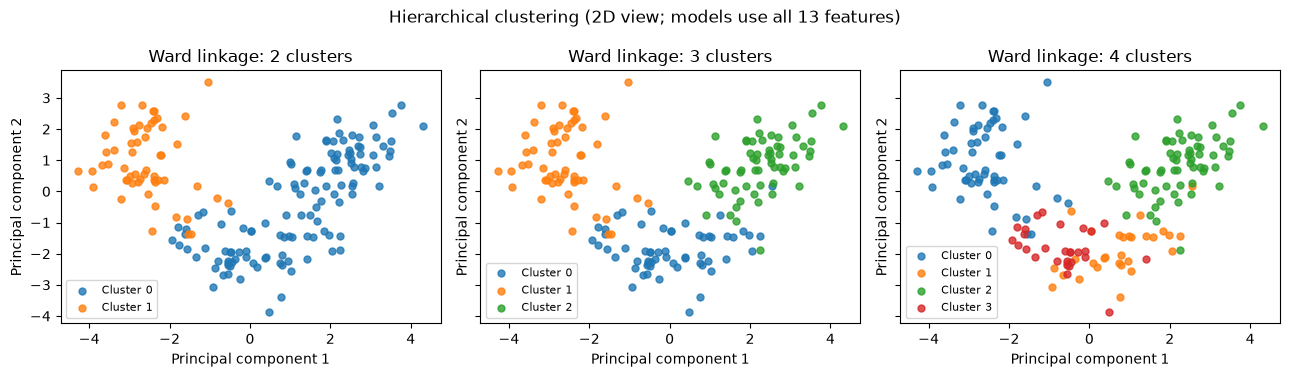

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, k in zip(axes, [2, 3, 4]):
    labels = hier_labels[k]
    for cluster in range(k):
        points = labels == cluster
        ax.scatter(X_plot[points, 0], X_plot[points, 1], s=25, alpha=0.8,
                   label=f'Cluster {cluster}')
    ax.set_title(f'Ward linkage: {k} clusters')
    ax.set_xlabel('Principal component 1')
    ax.set_ylabel('Principal component 2')
    ax.legend(fontsize=8)
fig.suptitle('Hierarchical clustering (2D view; models use all 13 features)')
fig.tight_layout()
plt.show()


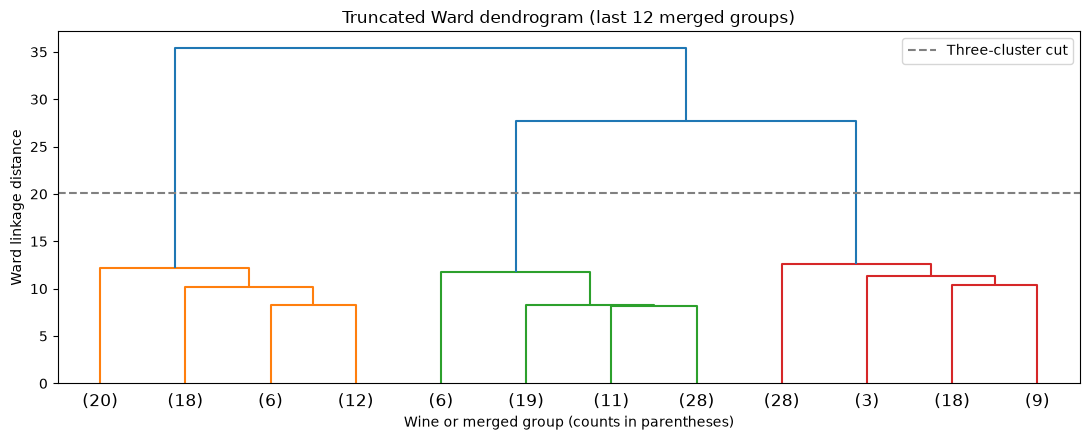

In [5]:
# The SciPy and scikit-learn trees use the same standardized data and Ward linkage.
tree = linkage(X, method='ward', metric='euclidean')
cut_for_three = (tree[-3, 2] + tree[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(tree, truncate_mode='lastp', p=12, show_leaf_counts=True,
           color_threshold=cut_for_three, ax=ax)
ax.axhline(cut_for_three, color='gray', linestyle='--', label='Three-cluster cut')
ax.set(title='Truncated Ward dendrogram (last 12 merged groups)',
       xlabel='Wine or merged group (counts in parentheses)',
       ylabel='Ward linkage distance')
ax.legend()
fig.tight_layout()
plt.show()


**Hierarchical interpretation.** The highest branches merge only at relatively large distances, suggesting broad groups. The dashed cut leaves three groups. In the tested values, three clusters have the highest silhouette and completeness, while four clusters slightly increase homogeneity but split existing groups. Ward assigns every wine to a cluster, including unusual wines.


## 3. DBSCAN
Test three neighborhood radii (`eps`) and two density thresholds (`min_samples`). Noise has label `-1`. Homogeneity and completeness treat noise as its own label and use all 178 wines. Silhouette uses only assigned wines and is shown as `NaN` unless at least two assigned clusters exist. Because the silhouette samples differ, compare its value alongside the noise count.


In [6]:
db_labels = {}
db_rows = []
for eps in [2.0, 2.3, 2.6]:
    for min_samples in [5, 8]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        db_labels[(eps, min_samples)] = labels
        assigned = labels != -1
        n_clusters = len(set(labels[assigned]))
        score = (silhouette_score(X[assigned], labels[assigned])
                 if 1 < n_clusters < assigned.sum() else np.nan)
        db_rows.append({
            'eps': eps, 'min_samples': min_samples,
            'clusters': n_clusters, 'noise': (~assigned).sum(),
            'silhouette_assigned': score,
            'homogeneity_all': homogeneity_score(true_class, labels),
            'completeness_all': completeness_score(true_class, labels),
        })
db_results = pd.DataFrame(db_rows)
print(db_results.round(3).to_string(index=False, na_rep='N/A'))


 eps  min_samples  clusters  noise  silhouette_assigned  homogeneity_all  completeness_all
 2.0            5         5     85                0.240            0.362             0.325
 2.0            8         3    117                0.436            0.390             0.469
 2.3            5         2     42                0.331            0.462             0.492
 2.3            8         2     52                0.342            0.404             0.427
 2.6            5         1     20                  N/A            0.052             0.161
 2.6            8         1     25                  N/A            0.062             0.167


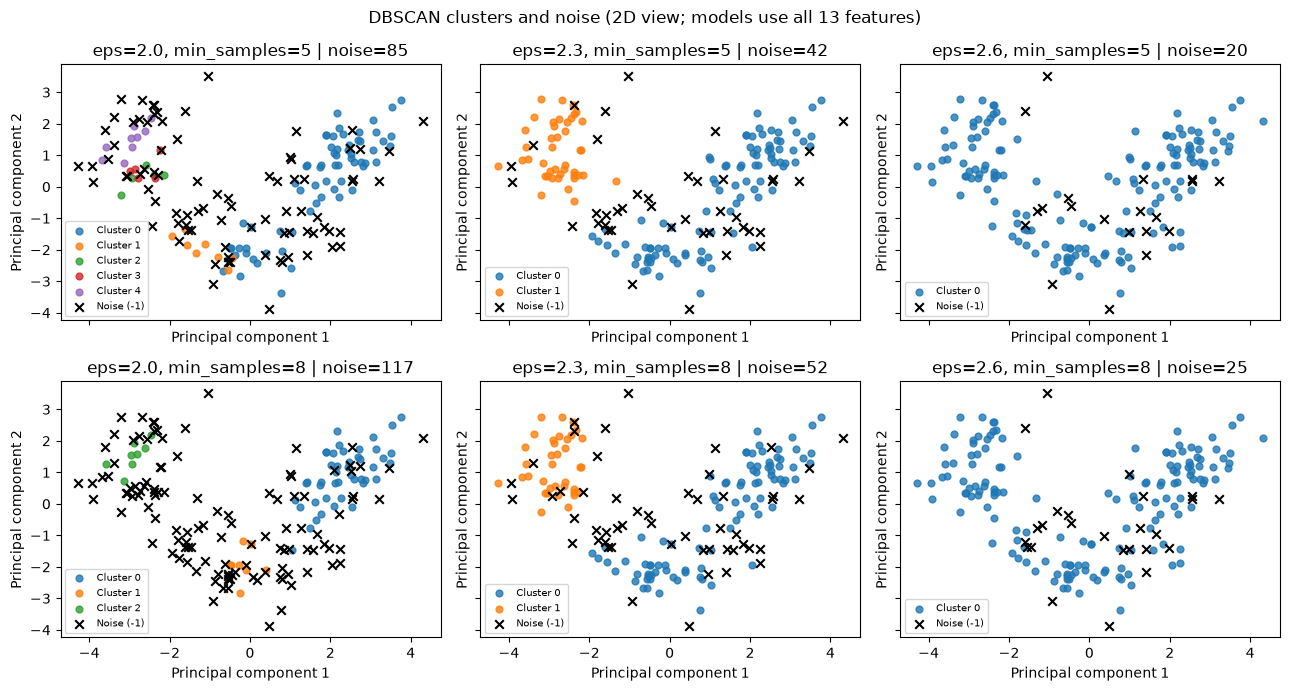

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for row, min_samples in enumerate([5, 8]):
    for col, eps in enumerate([2.0, 2.3, 2.6]):
        ax = axes[row, col]
        labels = db_labels[(eps, min_samples)]
        for cluster in sorted(set(labels) - {-1}):
            points = labels == cluster
            ax.scatter(X_plot[points, 0], X_plot[points, 1], s=24,
                       alpha=0.8, label=f'Cluster {cluster}')
        noise = labels == -1
        if noise.any():
            ax.scatter(X_plot[noise, 0], X_plot[noise, 1], marker='x',
                       color='black', s=38, label='Noise (-1)')
        ax.set_title(f'eps={eps}, min_samples={min_samples} | noise={noise.sum()}')
        ax.set_xlabel('Principal component 1')
        ax.set_ylabel('Principal component 2')
        ax.legend(fontsize=7, loc='best')
fig.suptitle('DBSCAN clusters and noise (2D view; models use all 13 features)')
fig.tight_layout()
plt.show()


## 4. Comparison and insights

- **Hierarchical:** With three clusters, silhouette is **0.277**, homogeneity **0.790**, and completeness **0.783**, using all 178 wines. Its dendrogram shows how groups join; the tradeoff is that it forces even unusual wines into a cluster.
- **DBSCAN:** At `eps=2.3`, `min_samples=5`, it finds **2 clusters and 42 noise points**; silhouette on the **136 assigned wines** is **0.331**, while homogeneity and completeness across **all 178** (noise as a label) are **0.462** and **0.492**. DBSCAN can flag unusual wines, but its grouping aligns less well with the three known classes here. The silhouette values are not directly comparable because DBSCAN excludes noise from that calculation.
- **Parameter effects:** At `eps=2.0`, `min_samples=5`, DBSCAN splits assigned wines into **5 clusters** and marks **85 as noise**. At `eps=2.6`, it merges assigned wines into **one cluster**, so silhouette is undefined. Increasing `min_samples` from 5 to 8 generally increases noise at the same radius. Hierarchical `n_clusters` directly controls the number of groups: two merges broad groups, while four splits one of the three-group solution.

The plots use two principal components for a readable view; all fits and distance-based silhouettes use the full standardized 13-feature data.
